# Model Complexity and Overfitting

**Overview**
In this exercise you will experiment with the impact of model complexity (higher order polynomial) and how it relates to Occam's Razor. 


<article class="message">
    <div class="message-body">
        <strong>List of tasks</strong>
        <ul style="list-style: none;">
            <li>
            <a href="#poly_re">Task 1:  Polynomial regression</a>
            </li>
            <li>
            <a href="#occam_train">Task 2: Train and evaluate linear models with po…</a>
            </li>
            <li>
            <a href="#plot_results">Task 3: Plot the polynomials (models)</a>
            </li>
            <li>
            <a href="#reflection">Task 4: Reflection</a>
            </li>
            <li>
            <a href="#Different_data_func">Task 5: Changing the data generating function</a>
            </li>
        </ul>
    </div>
</article>

<div style="float: right; width: 50%; justify-content: start" class="block is-clearfix">

<div class="has-text-centered">
<figure class="image is-inline-block" >

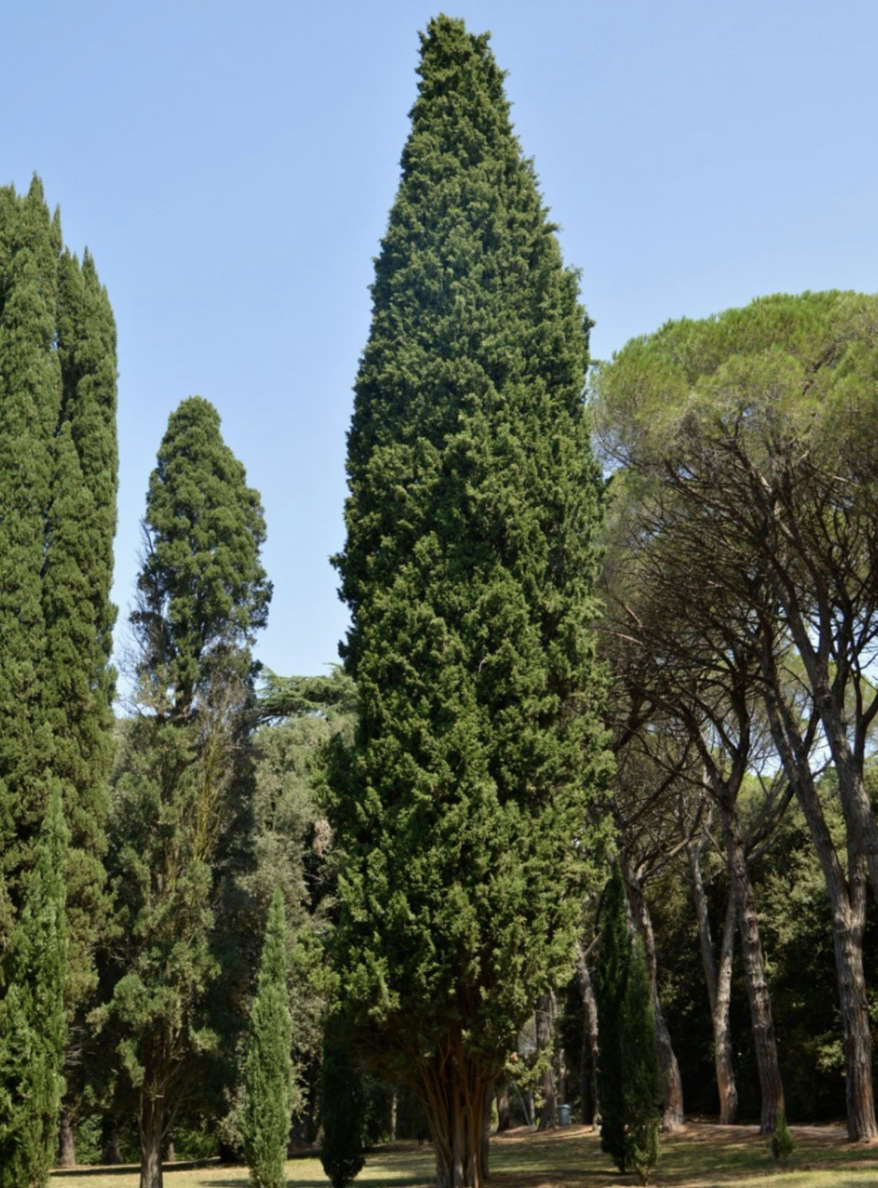


</figure>
</div>


</div>

This exercise is about making a regression model to predict the growth of Thuja Green Giant trees. You have to help the scientists decide which polynomial order best represents the training data to estimate future growth. To determine the optimal fit (model parameters), another group of researchers have provided you with  observation of height of their Thuja Green Giant trees from years later than currently observed by your team (`X_test`
 and `y_test`
). You will use this to choose the optimal model representing the growth of the Thuja Green Giant.
## Data
The following cell constructs and shows the data for the exercise. The data simulates growth (in meters) of one of the fastest growing trees, the Thuja Green Giant, each year. Scientists have observed and reported the growth of the tree for 7 years (`X_train`
 and `y_train`
), and now want to predict the future growth. 
The objective is to assist in making predictions based on this data. Additional data from another group has been provided to validate the hypothesis.
The scientists assume a polynomial relationship. 


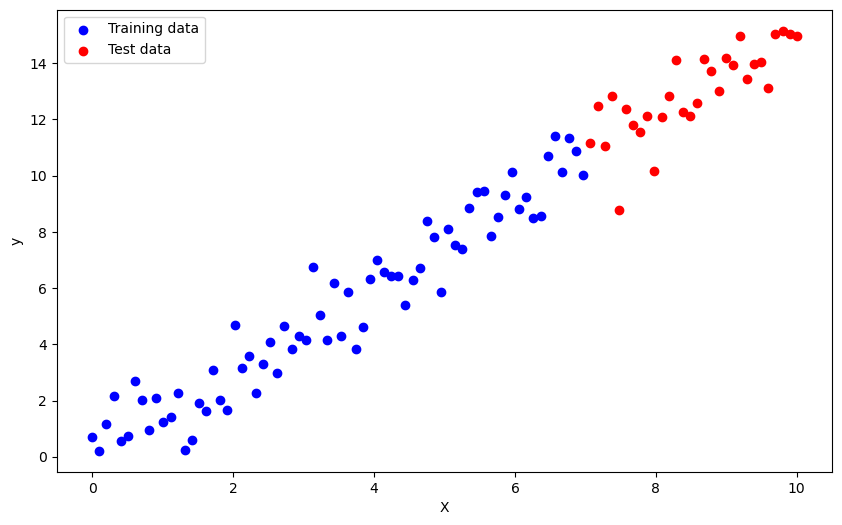

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
# Set a random seed for reproducibility
np.random.seed(42)

# Generate synthetic data
n_samples = 100
X = np.linspace(0, 10, n_samples).reshape(-1, 1)
y_true = 1.5 * X.ravel() + 0.2
# y_true = X.ravel() ** 2 + 1.5 * X.ravel() - 3 # Exercise 5
noise = np.random.normal(0, 1, n_samples)
y = y_true + noise

# Split the data into training and test sets
split_index = int(0.7 * n_samples)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]


# Plot the results
plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', label='Training data')
plt.scatter(X_test, y_test, color='red', label='Test data')
plt.xlabel('X')
plt.ylabel('y')
plt.legend()


---
**Task 1 (easy):  Polynomial regression👩‍💻**
1. In this exercise you may reuse polynomial regression using least squares
 from the previous exercise, or use the `PolynomialFeatures()`
 method from the [scikit-learn library](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html)
 to implement the `polynomial_regression()`
 method in the cell below. 


---

In [2]:
def polynomial_regression(X, y, degree):
    """
    Create and train a polynomial regression model of the desired degree.

    :param X: Training data features (years).
    :param y: Training data targets (heights).
    :param degree: Degree of the polynomial model.
    
    :return: Tuple containing predictions for training data and test data.
    """
    # Create polynomial features
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X) # Transform the features to polynomial features

    # Fit the model
    model = LinearRegression() # Linear least squares regression
    model.fit(X_poly, y) # Find model parameters
 
    # Predict on training data
    y_train_pred = model.predict(X_poly)

    # Predict on test data
    X_test_poly = poly.transform(X_test)
    y_test_pred = model.predict(X_test_poly)

    return y_train_pred, y_test_pred



---
**Task 2 (easy): Train and evaluate linear models with polynomial features👩‍💻**
1. Use the function `polynomial_regression`
 to perform polynomial regression for each order defined in the `degrees`
 variable and predict the outcome for both the test and training data. 
2. Implement the function `compute_mse`
 that based on the predictions of a model and the ground truth targets returns the _mean-squared-error_.


$$ MSE = \frac{1}{m}\sum_{i=1}^{m}(f_{\mathbf{w}}(x_{i})-y_{i})^2$$

**Hint**
You may save some time by modifying the implementation of the `rmse`
 function from the previous exercise.

3. For each polynomial model calculate the _mean-squared-error_ for both the training and test data (use `polynomial_regression`
 and `compute_mse`
).


---

In [3]:
def compute_mse(y_true, y_pred):
    """Compute Mean Squared Error between true and predicted values."""
    mse = np.mean((y_true - y_pred) ** 2)
    return mse

# Train and evaluate models with different polynomial degrees
degrees = [1, 2, 3, 4, 5, 6]
train_pred = []
test_pred = []
train_error = []
test_error = []

for degree in degrees:
    y_train_pred, y_test_pred = polynomial_regression(X_train, y_train, degree)
    train_pred.append(y_train_pred)
    test_pred.append(y_test_pred)
    train_error.append(compute_mse(y_train, y_train_pred))
    test_error.append(compute_mse(y_test, y_test_pred))


---
**Task 3 (easy): Plot the polynomials (models)👩‍💻**
Run the cell below to:
1. Plot the data so that training and test data have different colors.
2. Plot the predictions of the polynomial models over the scatter plot showing the given data. Perform this for both the training and test sets using X as input.


---

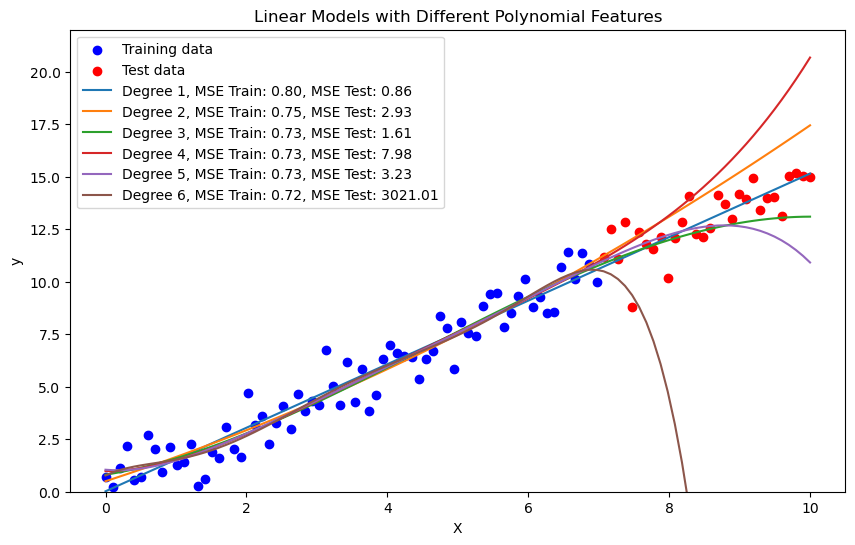

In [7]:
# Plot the results

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='blue', label='Training data')
plt.scatter(X_test, y_test, color='red', label='Test data')
for i, degree in enumerate(degrees):
    plt.plot(X, np.concatenate((train_pred[i],test_pred[i])), label=f'Degree {degree}, MSE Train: {train_error[i]:.2f}, MSE Test: {test_error[i]:.2f}')
plt.xlabel('X')
plt.ylabel('y')
plt.ylim(0,22)
plt.legend()
plt.title('Linear Models with Different Polynomial Features')
plt.show()



---
**Task 4 (medium): Reflection💡**
Reflect on:
1. Which model had the best performance  on the training data?
2. Which model had the best performance  on the test data?
3. How does the complexity (degree) of the model affect the performance on the training and test data?
4. Which model(s) shows signs of overfitting? How can you tell?


---

1. Which model had the best performance on the training data?
- The model with the highest degree (degree 6) had the best performance on the training data, achieving the lowest Mean Squared Error (MSE). This is because higher-degree polynomials can fit the training data more closely by capturing more complex patterns.

2. Which model had the best performance on the test data?
- The model of degree 1 (linear model) had the best performance on the test data, with the lowest MSE. This suggests that a simpler model generalizes better to unseen data in this case, avoiding the pitfalls of overfitting.

3. How does the complexity (degree) of the model affect the performance on the training and test data?
- As the degree of the polynomial increases, the model becomes more complex and fits the training data more closely, thereby reducing training error. However, this increased complexity often leads to higher test error due to overfitting. The model starts to capture noise specific to the training data, which doesn't generalize well to new, unseen data.

4. Which model(s) shows signs of overfitting? How can you tell?
- Models with degrees higher than 1 (especially degrees 4, 5, and 6) show signs of overfitting. This is evident from the decreasing training error but increasing test error as the model complexity increases. The models fit the training data exceptionally well but fail to perform adequately on the test data, indicating they have learned the noise rather than the underlying pattern.


---
**Task 5 (medium): Changing the data generating function👩‍💻💡**
How do the results change if the underlying function generating the data was changed to a 2. order polynomial, so that it e.g. simulates bacteria growth instead? 
1. Re-generate the data by replacing `y_true`
 with $y=f(x)=x^2+1.5x-3$ in the data generation step, and rerun the other code blocks.
2. Does it still make sense to follow the strategy of Occam's razor?


---

After modifying the data-generating function we notice:

- Higher-degree models (degrees 5 and 6) still achieve the lowest MSE on the training data due to their increased complexity and ability to fit the data closely.
- Models of degree 2 and 3 now have the lowest MSE on the test data. They outperform both the simpler linear model and the more complex higher-degree models.

Explanation:
- The true underlying relationship is quadratic. Therefore, a degree 2 polynomial model is sufficient to capture this relationship accurately.
- Higher-degree models overfit the training data by capturing noise, which leads to poorer generalization on the test data.

Conclusion:
- The degree 2 model provides the best balance between simplicity and performance, aligning with Occam's Razor.
- Increasing model complexity beyond what is necessary results in overfitting, highlighting the importance of selecting a model that matches the true complexity of the data.